# 01 — Data Cleaning and Exploration
CSV file with lithium price data and market data

In [26]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root from any nested notebook directory.
HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook somewhere inside the project folder containing src/features.py.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.features import create_lagged_features

DATA_FILE = REPO_ROOT / "Data" / "lithium_consolidated_monthly.csv"
RESULTS_DIR = REPO_ROOT / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42
df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Project root:", REPO_ROOT)
print("Data:", DATA_FILE)

Project root: /home/schmidlucy/Lucy-Schmid.github.io
Data: /home/schmidlucy/Lucy-Schmid.github.io/Data/lithium_consolidated_monthly.csv


## Dataset overview and missingness

In [27]:
print("Shape:",df.shape,"| Date range:",df.index.min(),"to",df.index.max())
print("Non-missing target observations:",df[TARGET].notna().sum())
coverage=pd.DataFrame({"Non-missing":df.notna().sum(),"Missing":df.isna().sum(),
 "First available":[df[c].first_valid_index() for c in df.columns],
 "Last available":[df[c].last_valid_index() for c in df.columns]})
coverage["Coverage (%)"]=(coverage["Non-missing"]/len(df)*100).round(1)
display(df[[TARGET]].describe().T); display(coverage.sort_values("Coverage (%)",ascending=False))
coverage.to_csv(TABLES_DIR/"data_coverage_audit.csv")

Shape: (209, 28) | Date range: 2009-06-01 00:00:00 to 2026-10-01 00:00:00
Non-missing target observations: 209


,count,mean,std,min,25%,50%,75%,max
Selected lithium carbonate price (CNY/t),209.0,103596.464115,107918.796632,30000.0,37000.0,68000.0,126000.0,540375.0


,Non-missing,Missing,First available,Last available,Coverage (%)
Selected lithium carbonate price (CNY/t),209,0,2009-06-01,2026-10-01,100.0
Selected target source,209,0,2009-06-01,2026-10-01,100.0
"Japan, Production - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Shipments - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Inventory - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",201,8,2010-01-01,2026-09-01,96.2
LME cobalt cash price (USD/metric tonne),197,12,2010-06-01,2026-10-01,94.3
China spot price low (CNY/t) - CSV,186,23,2009-06-01,2024-11-01,89.0
China spot price change (%) - CSV,186,23,2009-06-01,2024-11-01,89.0
China spot lithium carbonate price (CNY/t) - CSV,186,23,2009-06-01,2024-11-01,89.0


## Target price history

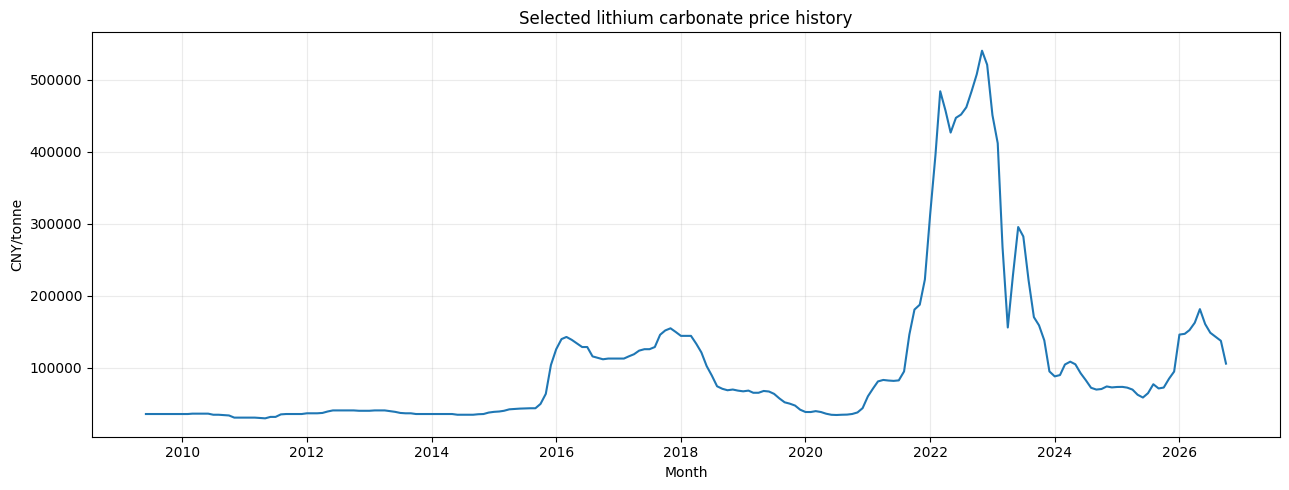

In [28]:
target=df[TARGET].dropna()
fig,ax=plt.subplots(figsize=(13,5)); ax.plot(target.index,target.values)
ax.set(title="Selected lithium carbonate price history",xlabel="Month",ylabel="CNY/tonne")
ax.grid(alpha=.25); plt.tight_layout(); fig.savefig(FIGURES_DIR/"01_target_price_history.png",dpi=180); plt.show()

## Missingness chart

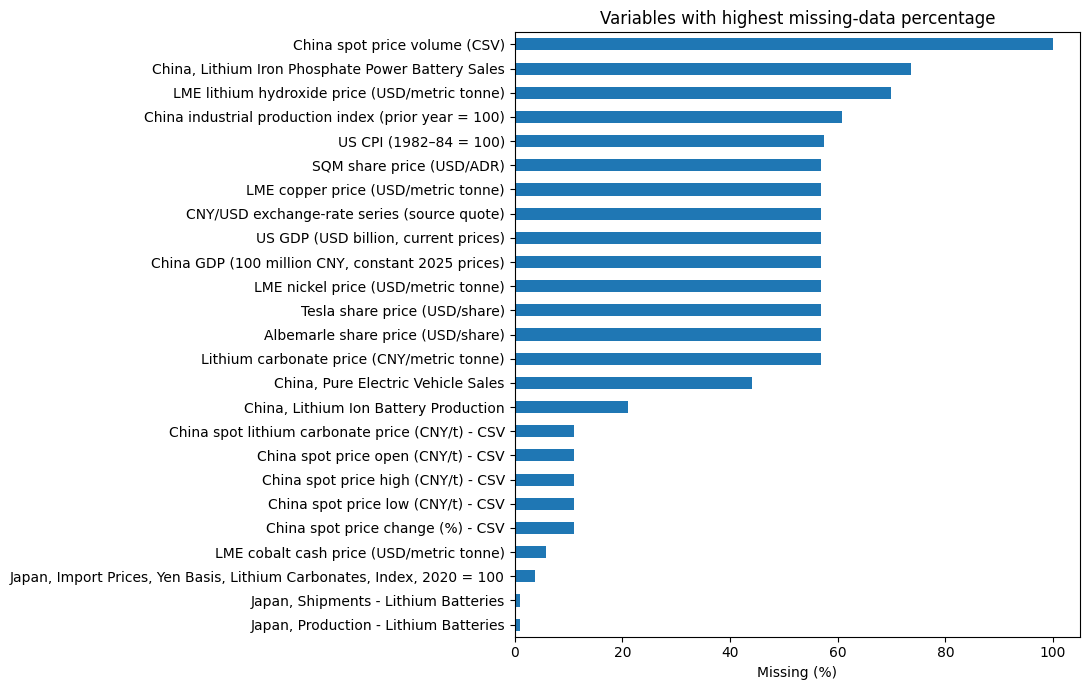

In [29]:
miss=(df.isna().mean()*100).sort_values(ascending=False).head(25).sort_values()
fig,ax=plt.subplots(figsize=(11,7)); miss.plot(kind="barh",ax=ax)
ax.set(title="Variables with highest missing-data percentage",xlabel="Missing (%)")
plt.tight_layout(); fig.savefig(FIGURES_DIR/"02_missingness.png",dpi=180); plt.show()

## Japan lithium carbonate import-price index
This series is an import-price index in yen (2020=100), not a directly comparable CNY/tonne spot price. It is evaluated as an optional predictor, not substituted for the target.

Japan index coverage: 201 2010-01-01 00:00:00 to 2026-09-01 00:00:00


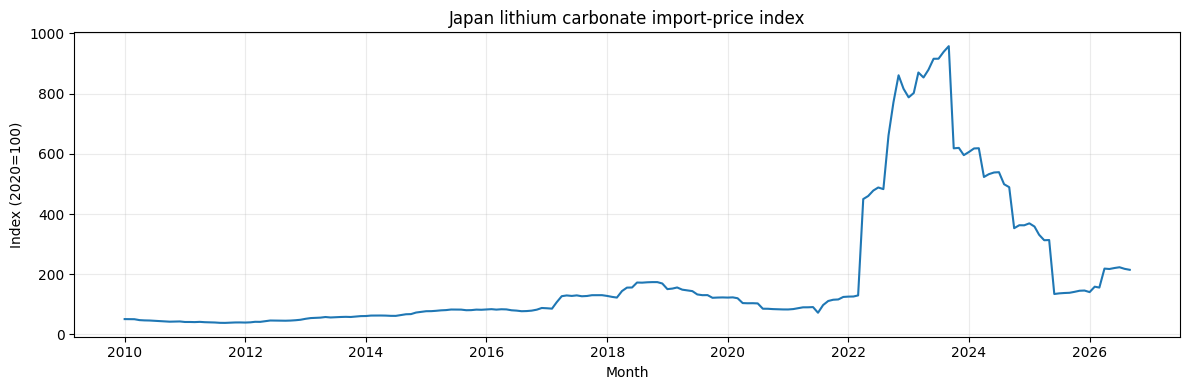

In [30]:
if JAPAN_INDEX in df.columns:
    s=df[JAPAN_INDEX].dropna()
    print("Japan index coverage:",len(s),s.index.min(),"to",s.index.max())
    fig,ax=plt.subplots(figsize=(12,4)); ax.plot(s.index,s.values)
    ax.set(title="Japan lithium carbonate import-price index",xlabel="Month",ylabel="Index (2020=100)")
    ax.grid(alpha=.25); plt.tight_layout(); fig.savefig(FIGURES_DIR/"03_japan_index.png",dpi=180); plt.show()

## Candidate predictor audit

In [31]:
excluded={TARGET,"Selected target source","Lithium carbonate price (CNY/metric tonne)",
"China spot lithium carbonate price (CNY/t) - CSV",
"China spot price open (CNY/t) - CSV","China spot price high (CNY/t) - CSV",
"China spot price low (CNY/t) - CSV","China spot price volume (CSV)","China spot price change (%) - CSV"}
predictors=[c for c in df.select_dtypes(include=np.number).columns if c not in excluded]
display(coverage.loc[[c for c in predictors if c in coverage.index]].sort_values("Coverage (%)",ascending=False))
df.to_csv(TABLES_DIR/"monthly_data_audited.csv")

,Non-missing,Missing,First available,Last available,Coverage (%)
"Japan, Production - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Shipments - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Inventory - Lithium Batteries",207,2,2009-06-01,2026-08-01,99.0
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",201,8,2010-01-01,2026-09-01,96.2
LME cobalt cash price (USD/metric tonne),197,12,2010-06-01,2026-10-01,94.3
"China, Lithium Ion Battery Production",165,44,2009-06-01,2025-03-01,78.9
"China, Pure Electric Vehicle Sales",117,92,2017-01-01,2026-10-01,56.0
SQM share price (USD/ADR),90,119,2019-05-01,2026-10-01,43.1
Albemarle share price (USD/share),90,119,2019-05-01,2026-10-01,43.1
CNY/USD exchange-rate series (source quote),90,119,2019-05-01,2026-10-01,43.1
